# Full-frame WCC g, r, i images of real galaxies from PHANGS-HST, and a colour composite

Two nearby spirals that fill the IMX455 frame (9568 x 6380 px, 2.7' x 1.8' at 16.87 mas/px):
**NGC 1300** (barred spiral, ACS F435W/F555W/F814W) and **NGC 4321 = M100** (grand-design, WFC3/UVIS
F438W/F555W/F814W). The source images are the PHANGS-HST drizzled mosaics (Lee et al. 2022; 0.04"/px,
e-/s, flux-calibrated), fetched on demand by `wcc_sim.phangs` into `~/.cache/wcc_sim/phangs` (~576 MB per band).

For each band `wcc_sim.ImageComponent` reprojects the mosaic onto the WCC frame WCS (surface brightness
conserved), converts e-/s through the HST AB zero point to WCC e-/s via a flat-AB spectrum in the ETC,
convolves with the WCC PSF and runs the usual noise model. Each frame is written as a full FITS product.
The Gaia catalogue is left empty: the foreground stars are already in the HST images.

**Read the frames with these caveats.**
- Resolution is set by HST (ACS PSF FWHM ~0.08-0.10") convolved with the WCC PSF (~3 px = 50 mas), so
  about 0.095" effective: roughly 2x coarser than WCC alone. No optical data of NGC galaxies does better.
- Bands are mapped, not transformed: F435W/F438W -> g, F555W -> r, F814W -> i. Pivots differ by 50-100 nm.
- HST sky-subtraction residuals and saturated-star artefacts ride along; negatives are clipped to zero.

In [1]:
import os, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import AsinhNorm
from astropy.visualization import make_lupton_rgb

from wcc_sim import simulate_field
from wcc_sim.catalog import _empty_table
from wcc_sim.phangs import phangs_component, fetch_phangs

OUT = 'phangs_out'; os.makedirs(OUT, exist_ok=True)

GALAXIES = {   # pointing centre; frame long axis along RA (pa=0) puts the NGC 1300 bar along x
    'ngc1300': (49.9208, -19.4111),
    'ngc4321': (185.7288, 15.8223),
}
BANDS = 'gri'
EXPTIME = 600.0

def block_mean(a, n):
    ny, nx = ((s // n) * n for s in a.shape)
    return a[:ny, :nx].reshape(ny // n, n, nx // n, n).mean(axis=(1, 3))

## Fetch the mosaics (downloads once, then cached)

In [2]:
for gal in GALAXIES:
    for b in BANDS:
        t0 = time.time()
        p = fetch_phangs(gal, b)
        print(f"{gal} {b}: {p.name}  {p.stat().st_size / 1e6:.0f} MB  ({time.time() - t0:.0f} s)")

ngc1300 g: hlsp_phangs-hst_hst_acs-wfc_ngc1300mosaic_f435w_v1_exp-drc-sci.fits  576 MB  (0 s)


ngc1300 r: hlsp_phangs-hst_hst_acs-wfc_ngc1300mosaic_f555w_v1_exp-drc-sci.fits  576 MB  (0 s)


ngc1300 i: hlsp_phangs-hst_hst_acs-wfc_ngc1300mosaic_f814w_v1_exp-drc-sci.fits  576 MB  (0 s)


ngc4321 g: hlsp_phangs-hst_hst_wfc3-uvis_ngc4321mosaic_f438w_v1_exp-drc-sci.fits  400 MB  (0 s)


ngc4321 r: hlsp_phangs-hst_hst_wfc3-uvis_ngc4321mosaic_f555w_v1_exp-drc-sci.fits  400 MB  (0 s)


ngc4321 i: hlsp_phangs-hst_hst_wfc3-uvis_ngc4321mosaic_f814w_v1_exp-drc-sci.fits  400 MB  (0 s)


## Simulate one full IMX455 frame per band and write the FITS products

600 s in each of g, r, i. The printed numbers are the electrons in the frame (galaxy plus sky and dark), the
peak pixel, and how many pixels saturate (none expected: a 21 mag/arcsec$^2$ disk is only ~8 e-/px here).

In [3]:
frames = {}
for gal, (ra, dec) in GALAXIES.items():
    for b in BANDS:
        t0 = time.time()
        comp = phangs_component(gal, b)
        f = simulate_field(ra, dec, sensorfilter=f'zwo:{b}', exptime=EXPTIME, catalog=_empty_table(),
                           extended_sources=[comp], seed=11, output=f'{OUT}/{gal}_{b}.fits')
        frames[gal, b] = f.image_adu.astype(np.float32)
        print(f"{gal} {b}: {f.image_clean.sum():.2e} e- in frame (galaxy + sky + dark), peak {f.image_clean.max():.0f} e-, "
              f"{int(f.saturation_mask.sum())} saturated px, {time.time() - t0:.0f} s -> {OUT}/{gal}_{b}.fits")
        del comp, f

ngc1300 g: 1.25e+09 e- in frame (galaxy + sky + dark), peak 8603 e-, 0 saturated px, 39 s -> phangs_out/ngc1300_g.fits


ngc1300 r: 1.23e+09 e- in frame (galaxy + sky + dark), peak 15716 e-, 0 saturated px, 38 s -> phangs_out/ngc1300_r.fits


ngc1300 i: 7.94e+08 e- in frame (galaxy + sky + dark), peak 6231 e-, 0 saturated px, 35 s -> phangs_out/ngc1300_i.fits


ngc4321 g: 1.38e+09 e- in frame (galaxy + sky + dark), peak 49687 e-, 94 saturated px, 28 s -> phangs_out/ngc4321_g.fits


ngc4321 r: 1.29e+09 e- in frame (galaxy + sky + dark), peak 34048 e-, 84 saturated px, 28 s -> phangs_out/ngc4321_r.fits


ngc4321 i: 8.10e+08 e- in frame (galaxy + sky + dark), peak 16647 e-, 5 saturated px, 29 s -> phangs_out/ngc4321_i.fits


## The three bands, 4x4 binned for display

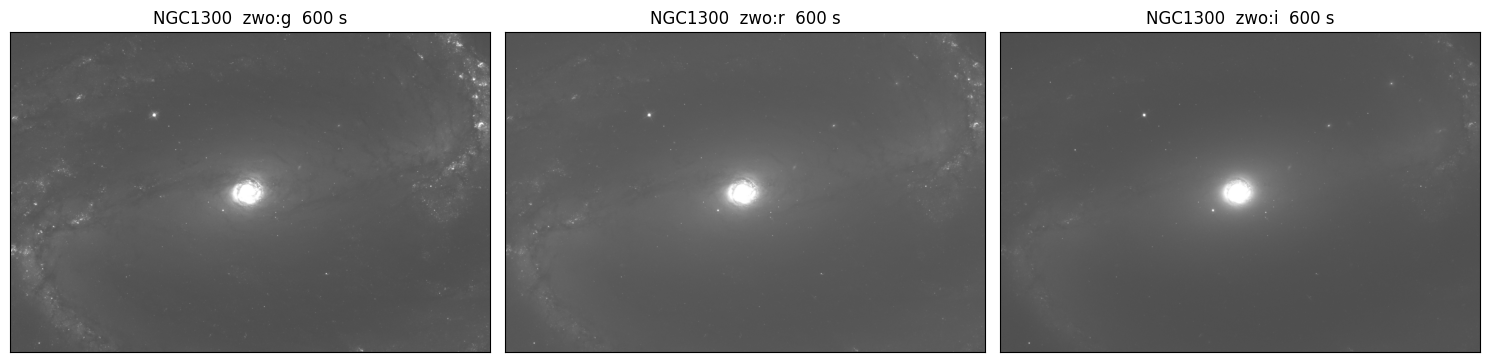

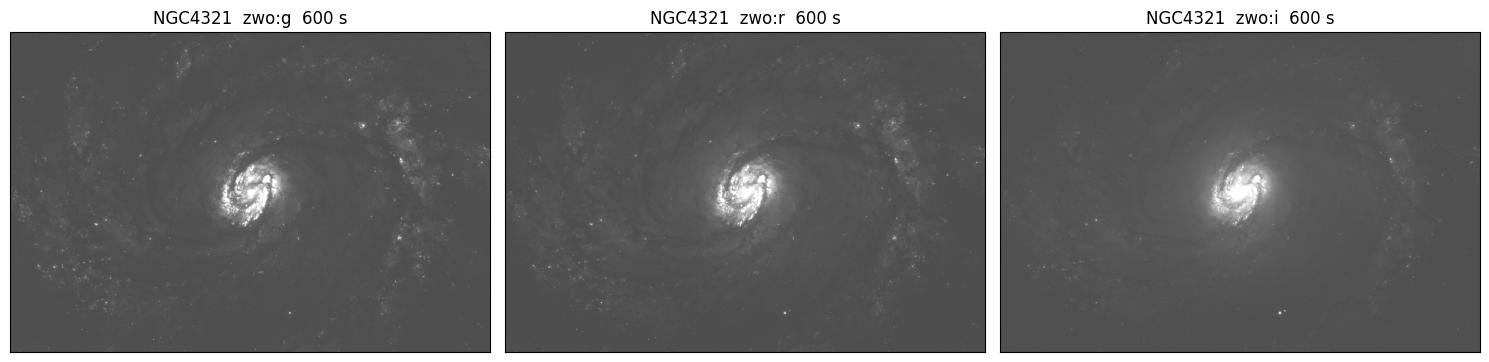

In [4]:
for gal in GALAXIES:
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
    for ax, b in zip(axes, BANDS):
        img = block_mean(frames[gal, b], 4)
        sky = np.median(img)
        ax.imshow(img - sky, origin='lower', cmap='gray',
                  norm=AsinhNorm(linear_width=5 * img.std(), vmin=-3 * img.std(),
                                 vmax=np.percentile(img - sky, 99.8)))
        ax.set(title=f'{gal.upper()}  zwo:{b}  {EXPTIME:.0f} s', xticks=[], yticks=[])
    fig.tight_layout()

## Colour composites: i, r, g -> R, G, B (Lupton et al. 2004 asinh stretch)

Left: the full frame, 4x4 binned. Right: a 1500 x 1500 px (25") crop of the centre at native WCC sampling.

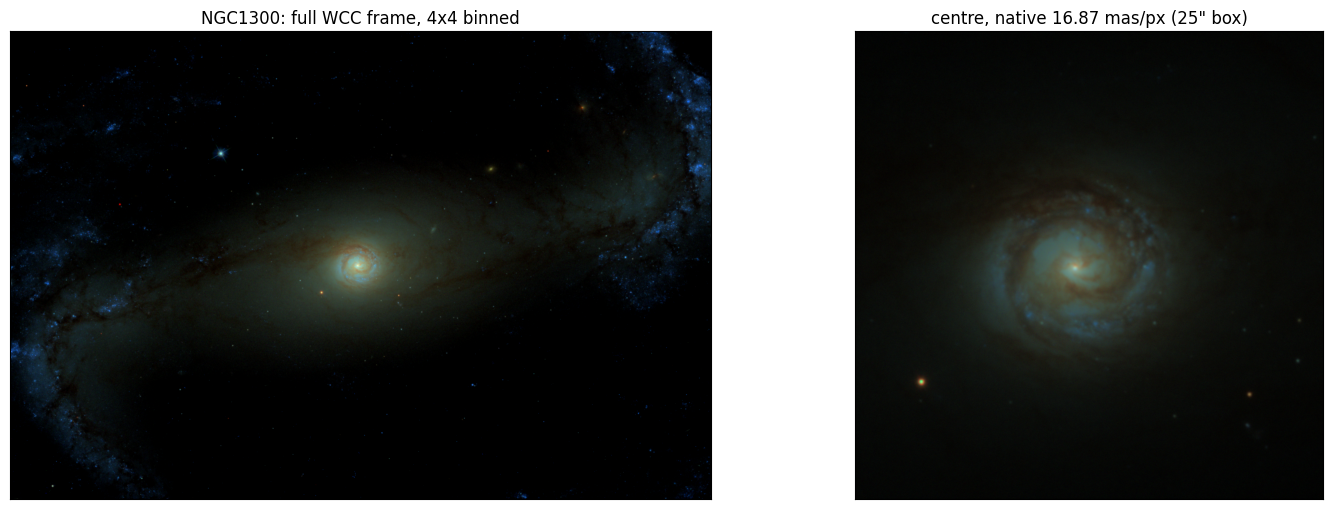

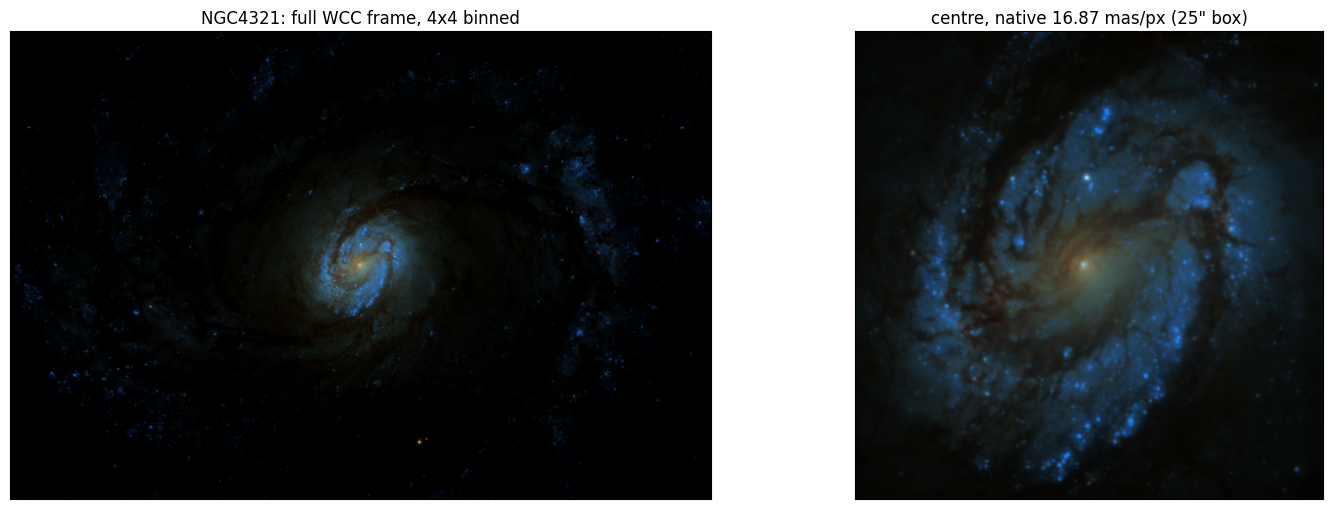

In [5]:
def rgb(gal, n_bin=1, crop=None):
    chans = []
    for b in 'irg':
        img = frames[gal, b]
        if crop is not None:
            cy, cx = (s // 2 for s in img.shape)
            img = img[cy - crop // 2: cy + crop // 2, cx - crop // 2: cx + crop // 2]
        if n_bin > 1:
            img = block_mean(img, n_bin)
        chans.append(img - np.median(frames[gal, b]))
    stretch = np.percentile(chans[1], 99.5)
    return make_lupton_rgb(*chans, Q=8, stretch=stretch, minimum=0)

for gal in GALAXIES:
    fig, (a0, a1) = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={'width_ratios': [1.5, 1]})
    a0.imshow(rgb(gal, n_bin=4), origin='lower'); a0.set(title=f'{gal.upper()}: full WCC frame, 4x4 binned')
    a1.imshow(rgb(gal, crop=1500), origin='lower'); a1.set(title='centre, native 16.87 mas/px (25" box)')
    for ax in (a0, a1): ax.set(xticks=[], yticks=[])
    fig.tight_layout()
    fig.savefig(f'{OUT}/{gal}_rgb.png', dpi=150)

In [6]:
for fn in sorted(os.listdir(OUT)):
    print(f"{fn:28s} {os.path.getsize(os.path.join(OUT, fn)) / 1e6:7.1f} MB")

ngc1300_g.fits                 549.4 MB
ngc1300_i.fits                 549.4 MB
ngc1300_r.fits                 549.4 MB
ngc1300_rgb.png                  1.6 MB
ngc4321_g.fits                 549.4 MB
ngc4321_i.fits                 549.4 MB
ngc4321_r.fits                 549.4 MB
ngc4321_rgb.png                  1.5 MB
